# 06 — Insights de panes veiculares (2021–2026)

**Fonte:** seis CSVs anuais. **Recorte:** nove municípios da Baixada Santista. **Objetivo:** análise exploratória e exportações para Power BI.

Os dados representam **ocorrências de panes veiculares em rodovias**. Não demonstram por si só interrupções no canal marítimo nem efeito causal de condições climáticas. 2026 pode estar incompleto.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
while ROOT.name != 'porto-santos' and not (ROOT / 'data/processed/panes_veiculares').exists():
    if ROOT == ROOT.parent:
        raise FileNotFoundError('Abra o notebook dentro da pasta porto-santos.')
    ROOT = ROOT.parent

PASTA = ROOT / 'data' / 'processed' / 'panes_veiculares'
ARQUIVO = PASTA / 'panes_veiculares_baixada_limpo_2021_2026.csv'
if not ARQUIVO.exists():
    raise FileNotFoundError(f'Execute primeiro src/panes_veiculares/clean_panes_veiculares.py: {ARQUIVO}')
df = pd.read_csv(ARQUIVO, encoding='utf-8-sig', low_memory=False)
df['DATA'] = pd.to_datetime(df['DATA'], errors='coerce')
df['DATA_HORA'] = pd.to_datetime(df['DATA_HORA'], errors='coerce')
print('Linhas:',len(df),'| Colunas:',len(df.columns))
display(df.head(3))

Linhas: 212628 | Colunas: 36


,ID,CONCESSIONARIA,RODOVIA,KM,SENTIDO,PERIMETRO,PANE_TIPO,MUNICIPIO,REGIAO_ADMINISTRATIVA,DATA,...,FLAG_MUNICIPIO_AUSENTE,FLAG_RODOVIA_AUSENTE,QUALIDADE_STATUS,ANO,MES,DIA,HORA_NUM,MUNICIPIO_NORMALIZADO,RECORTE_BAIXADA,CORREDOR_PRINCIPAL_ACESSO
0,5_6419774,L22-ECOVIAS IMIGRANTES,SP160,47.8,SUL,URBANO,PANE MECÂNICA,SÃO VICENTE,BAIXADA SANTISTA,2021-01-01,...,False,False,OK,2021,1,1,2,SAO VICENTE,True,True
1,5_6419775,L22-ECOVIAS IMIGRANTES,SP150,44.4,NORTE,URBANO,PANE MECÂNICA,CUBATÃO,BAIXADA SANTISTA,2021-01-01,...,False,False,OK,2021,1,1,2,CUBATAO,True,True
2,5_6419789,L22-ECOVIAS IMIGRANTES,SP160,56.5,NORTE,URBANO,PANE MECÂNICA,CUBATÃO,BAIXADA SANTISTA,2021-01-01,...,False,False,OK,2021,1,1,3,CUBATAO,True,True


## 1. Qualidade e rastreabilidade
Registros sinalizados não são excluídos automaticamente. Filtros temporais usam datas válidas; gráficos por categoria também podem incluir valores ausentes.

In [2]:
print('Registros por status:')
display(df['QUALIDADE_STATUS'].value_counts(dropna=False).rename_axis('status').reset_index(name='registros'))
flags = [c for c in df if c.startswith('FLAG_')]
qualidade = pd.DataFrame({'regra':flags,'ocorrencias':[int(df[c].sum()) for c in flags]})
display(qualidade)
ausencia = (df.isna().mean()*100).round(2).sort_values(ascending=False).rename('ausencia_pct').reset_index().rename(columns={'index':'coluna'})
display(ausencia.head(20))

Registros por status:


,status,registros
0,OK,212614
1,REVISAR,14


,regra,ocorrencias
0,FLAG_ID_DUPLICADO,0
1,FLAG_DATA_INVALIDA,0
2,FLAG_HORA_INVALIDA,0
3,FLAG_ANO_DIVERGENTE,0
4,FLAG_KM_INVALIDO,0
5,FLAG_COORDENADA_INVALIDA,3
6,FLAG_COORDENADA_FORA_SP_APROX,11
7,FLAG_ID_AUSENTE,0
8,FLAG_MUNICIPIO_AUSENTE,0
9,FLAG_RODOVIA_AUSENTE,0


,coluna,ausencia_pct
0,ID,0.0
1,CONCESSIONARIA,0.0
2,RODOVIA,0.0
3,KM,0.0
4,SENTIDO,0.0
5,PERIMETRO,0.0
6,PANE_TIPO,0.0
7,MUNICIPIO,0.0
8,REGIAO_ADMINISTRATIVA,0.0
9,DATA,0.0


## 2. Evolução anual e comparação de anos completos

,ANO_ARQUIVO,ocorrencias,municipios
0,2021,36487,4
1,2022,35700,4
2,2023,36645,4
3,2024,34741,8
4,2025,38353,8
5,2026,30702,8


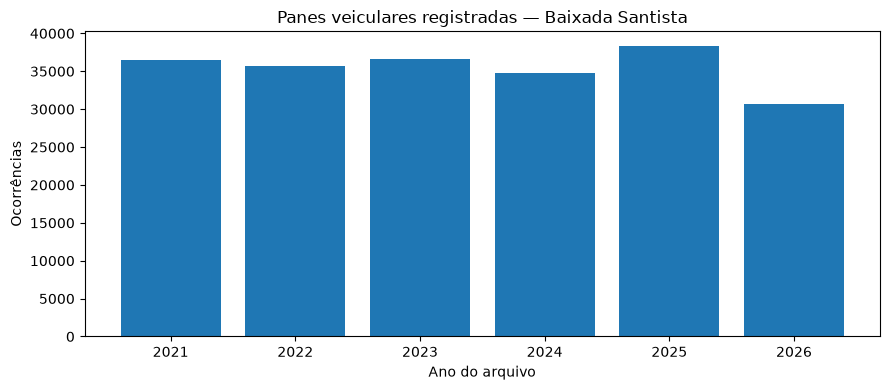

Nota: não comparar diretamente 2026 com anos inteiros sem recortar os mesmos meses.


In [3]:
anual = df.groupby('ANO_ARQUIVO',as_index=False).agg(ocorrencias=('ID','size'),municipios=('MUNICIPIO_NORMALIZADO','nunique'))
display(anual)
plt.figure(figsize=(9,4))
plt.bar(anual['ANO_ARQUIVO'].astype(str),anual['ocorrencias'])
plt.title('Panes veiculares registradas — Baixada Santista')
plt.xlabel('Ano do arquivo');plt.ylabel('Ocorrências');plt.tight_layout();plt.show()
print('Nota: não comparar diretamente 2026 com anos inteiros sem recortar os mesmos meses.')

## 3. Sazonalidade por mês

,ANO,MES,ocorrencias,ids_distintos,data_mes
0,2021,1,4673,4673,2021-01-01
1,2021,2,3193,3193,2021-02-01
2,2021,3,2547,2547,2021-03-01
3,2021,4,2171,2171,2021-04-01
4,2021,5,2689,2689,2021-05-01
5,2021,6,2488,2488,2021-06-01
6,2021,7,2598,2598,2021-07-01
7,2021,8,2991,2991,2021-08-01
8,2021,9,3094,3094,2021-09-01
9,2021,10,2682,2682,2021-10-01


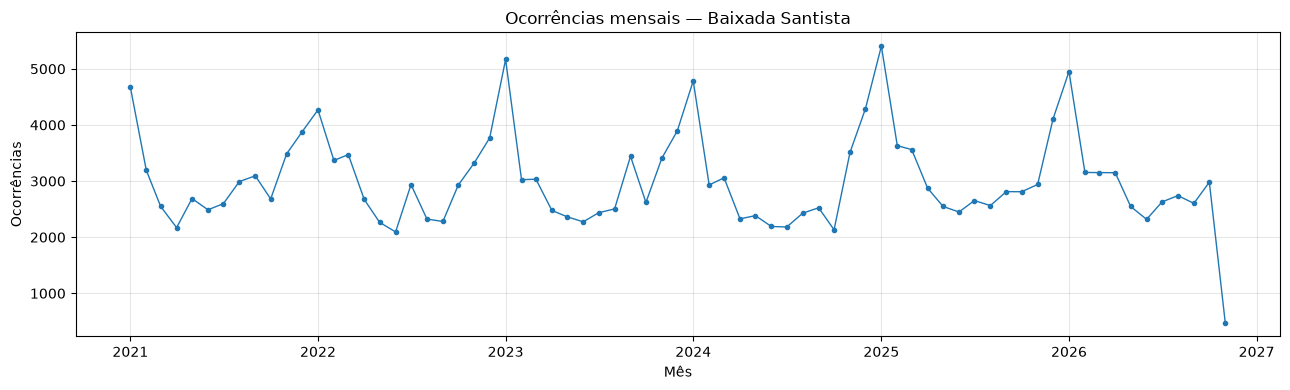

In [4]:
mensal = df.dropna(subset=['DATA']).groupby(['ANO','MES'],as_index=False).agg(ocorrencias=('ID','size'),ids_distintos=('ID','nunique'))
mensal['data_mes'] = pd.to_datetime(dict(year=mensal['ANO'],month=mensal['MES'],day=1))
display(mensal.head(12))
plt.figure(figsize=(13,4))
plt.plot(mensal['data_mes'],mensal['ocorrencias'],marker='.',linewidth=1)
plt.title('Ocorrências mensais — Baixada Santista');plt.xlabel('Mês');plt.ylabel('Ocorrências');plt.grid(alpha=.3);plt.tight_layout();plt.show()

## 4. Tipos de pane mais frequentes

,PANE_TIPO,ocorrencias,percentual
1,PANE MECÂNICA,198893,93.54
0,PANE ELÉTRICA,8255,3.88
2,PANE SECA,5480,2.58


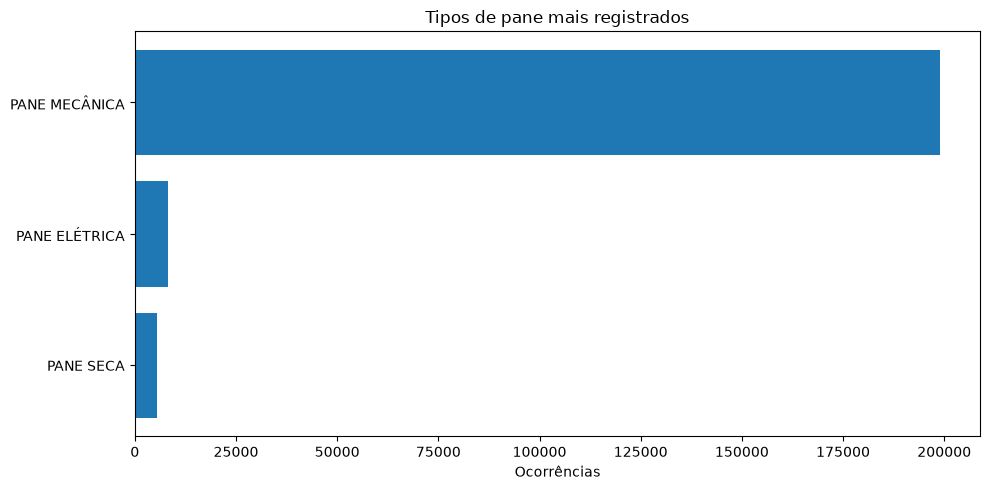

In [5]:
tipos = df.groupby('PANE_TIPO',dropna=False).size().reset_index(name='ocorrencias').sort_values('ocorrencias',ascending=False)
tipos['percentual']=(100*tipos['ocorrencias']/len(df)).round(2)
display(tipos.head(15))
plt.figure(figsize=(10,5))
top=tipos.head(10).iloc[::-1]
plt.barh(top['PANE_TIPO'].fillna('Não informado').astype(str),top['ocorrencias'])
plt.title('Tipos de pane mais registrados');plt.xlabel('Ocorrências');plt.tight_layout();plt.show()

## 5. Rodovias e municípios — distribuição de ocorrências

,RODOVIA,ocorrencias
4,SP160,86038
0,SP055,68795
3,SP150,46917
5,SPA248/055,4161
1,SP098,3118
8,SPI059/150,1995
6,SPA291/055,1178
9,SPM150D,335
2,SP148,50
7,SPA344/055,41


,MUNICIPIO_NORMALIZADO,ocorrencias
1,CUBATAO,92931
7,SAO VICENTE,72090
6,SANTOS,27437
5,PRAIA GRANDE,9066
0,BERTIOGA,5466
2,ITANHAEM,2891
3,MONGAGUA,1657
4,PERUIBE,1090


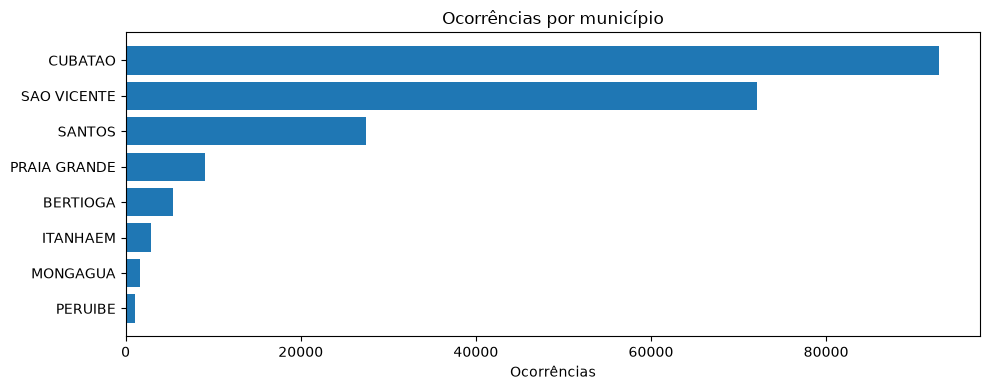

In [6]:
rodovias = df.groupby('RODOVIA',dropna=False).size().reset_index(name='ocorrencias').sort_values('ocorrencias',ascending=False)
municipios = df.groupby('MUNICIPIO_NORMALIZADO',dropna=False).size().reset_index(name='ocorrencias').sort_values('ocorrencias',ascending=False)
display(rodovias.head(15)); display(municipios)
plt.figure(figsize=(10,4))
top=municipios.head(9).iloc[::-1]
plt.barh(top['MUNICIPIO_NORMALIZADO'].astype(str),top['ocorrencias'])
plt.title('Ocorrências por município');plt.xlabel('Ocorrências');plt.tight_layout();plt.show()

## 6. Perfil dos veículos e horários

,GRUPO_VEICULO,ocorrencias
0,AUTOMÓVEL,133407
2,CAMINHÃO,63197
3,MOTOCICLETA,14042
4,OUTROS,1916
1,BICICLETA,66


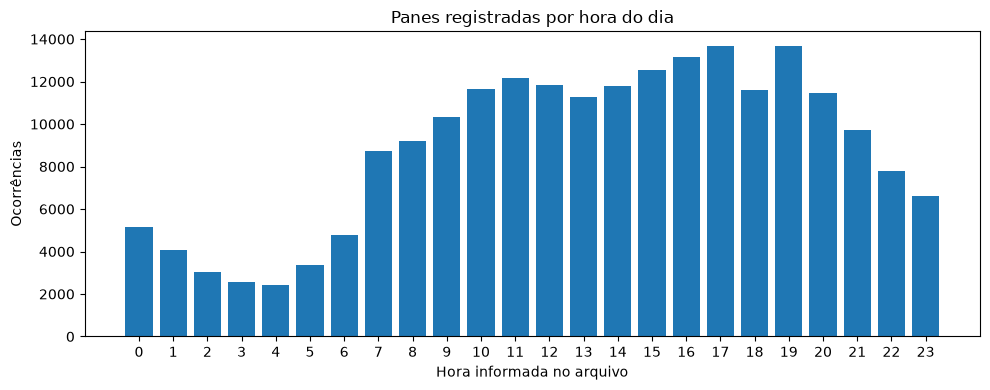

In [7]:
veiculos = df.groupby('GRUPO_VEICULO',dropna=False).size().reset_index(name='ocorrencias').sort_values('ocorrencias',ascending=False)
horarios = df.dropna(subset=['HORA_NUM']).groupby('HORA_NUM',as_index=False).size().rename(columns={'size':'ocorrencias'})
display(veiculos.head(15))
plt.figure(figsize=(10,4))
plt.bar(horarios['HORA_NUM'],horarios['ocorrencias'])
plt.xticks(range(0,24));plt.title('Panes registradas por hora do dia');plt.xlabel('Hora informada no arquivo');plt.ylabel('Ocorrências');plt.tight_layout();plt.show()

## 7. Indicadores diários para integração futura com outras bases
A agregação é por **data**, sem assumir automaticamente que os horários informados estão em UTC.

In [8]:
diario = df.dropna(subset=['DATA']).groupby('DATA',as_index=False).agg(ocorrencias=('ID','size'),municipios=('MUNICIPIO_NORMALIZADO','nunique'),qtd_para_revisao=('QUALIDADE_STATUS',lambda s:(s=='REVISAR').sum()))
diario['ano']=diario['DATA'].dt.year
diario['mes']=diario['DATA'].dt.month
display(diario.sort_values('ocorrencias',ascending=False).head(15))

,DATA,ocorrencias,municipios,qtd_para_revisao,ano,mes
1463,2025-01-03,533,8,1,2025,1
732,2023-01-03,500,4,0,2023,1
1462,2025-01-02,443,8,0,2025,1
731,2023-01-02,435,4,0,2023,1
367,2022-01-03,392,4,0,2022,1
1096,2024-01-02,385,4,0,2024,1
1828,2026-01-03,363,8,0,2026,1
1837,2026-01-12,358,8,0,2026,1
1461,2025-01-01,333,8,0,2025,1
1464,2025-01-04,329,8,0,2025,1


## 8. Indicadores por rodovia, município e mês

In [9]:
municipio_mes = df.dropna(subset=['DATA']).groupby(['ANO','MES','MUNICIPIO_NORMALIZADO'],as_index=False).size().rename(columns={'size':'ocorrencias'})
rodovia_mes = df.dropna(subset=['DATA']).groupby(['ANO','MES','RODOVIA'],dropna=False,as_index=False).size().rename(columns={'size':'ocorrencias'})
rodovia_tipo = df.groupby(['RODOVIA','PANE_TIPO'],dropna=False).size().reset_index(name='ocorrencias').sort_values('ocorrencias',ascending=False)
display(rodovia_mes.sort_values('ocorrencias',ascending=False).head(10))

,ANO,MES,RODOVIA,ocorrencias
135,2023,1,SP160,2405
207,2024,1,SP160,2266
2,2021,1,SP160,2266
284,2025,1,SP160,2209
64,2022,1,SP160,1948
201,2023,12,SP160,1849
402,2026,1,SP160,1836
129,2022,12,SP160,1778
273,2024,12,SP055,1773
281,2025,1,SP055,1758


## 9. Insights objetivos gerados automaticamente

In [10]:
print(f'Total de ocorrências na Baixada: {len(df):,}'.replace(',','.'))
print('Tipo mais frequente:',tipos.iloc[0]['PANE_TIPO'],'—',int(tipos.iloc[0]['ocorrencias']))
print('Município com mais registros:',municipios.iloc[0]['MUNICIPIO_NORMALIZADO'],'—',int(municipios.iloc[0]['ocorrencias']))
print('Rodovia com mais registros:',rodovias.iloc[0]['RODOVIA'],'—',int(rodovias.iloc[0]['ocorrencias']))
print('Registros sinalizados para revisão:',int((df['QUALIDADE_STATUS']=='REVISAR').sum()))
print('Maior dia observado:',diario.sort_values('ocorrencias',ascending=False).head(1)[['DATA','ocorrencias']].to_string(index=False))
print('ATENÇÃO: números absolutos não são taxas de panes por veículo ou por tráfego. Não permitem concluir risco proporcional.')

Total de ocorrências na Baixada: 212.628
Tipo mais frequente: PANE MECÂNICA — 198893
Município com mais registros: CUBATAO — 92931
Rodovia com mais registros: SP160 — 86038
Registros sinalizados para revisão: 14
Maior dia observado:       DATA  ocorrencias
2025-01-03          533
ATENÇÃO: números absolutos não são taxas de panes por veículo ou por tráfego. Não permitem concluir risco proporcional.


## 9A. Recorte dos corredores principais de acesso terrestre
Para o acesso ao Porto de Santos, distinguimos o conjunto regional dos eventos em **SP-150 (Anchieta)** e **SP-160 (Imigrantes)**. Os eventos nessas rodovias ainda não demonstram, por si sós, interrupção do acesso, congestionamento ou causa climática.


In [12]:
from pathlib import Path

# Localizar a raiz do projeto
ROOT = Path.cwd().resolve()

while ROOT.name != "porto-santos":
    if ROOT == ROOT.parent:
        raise FileNotFoundError(
            "Não foi possível localizar a pasta porto-santos."
        )
    ROOT = ROOT.parent

# Pasta onde os CSVs serão salvos
DESTINO = ROOT / "data" / "processed" / "panes_veiculares"
DESTINO.mkdir(parents=True, exist_ok=True)

# Selecionar ocorrências nos principais corredores
corredores = df.loc[
    df["RODOVIA"]
    .astype("string")
    .str.strip()
    .str.upper()
    .isin(["SP150", "SP160"])
].copy()

print("Ocorrências nos principais corredores:", len(corredores))

# Quantidade de ocorrências por ano e rodovia
display(
    corredores.groupby(["ANO_ARQUIVO", "RODOVIA"])
    .size()
    .unstack(fill_value=0)
)

# Exportar CSV dos corredores
corredores.to_csv(
    DESTINO / "panes_corredores_principais_acesso_2021_2026.csv",
    index=False,
    encoding="utf-8-sig"
)

# Criar resumo diário
corredores_diario = (
    corredores.dropna(subset=["DATA"])
    .groupby(["DATA", "RODOVIA"])
    .size()
    .reset_index(name="ocorrencias")
)

# Exportar CSV diário
corredores_diario.to_csv(
    DESTINO / "panes_corredores_acesso_diario.csv",
    index=False,
    encoding="utf-8-sig"
)

# Resumo por rodovia
display(
    corredores.groupby("RODOVIA")
    .size()
    .reset_index(name="ocorrencias")
)

print("\nCSVs gerados com sucesso!")
print("Pasta:", DESTINO)


Ocorrências nos principais corredores: 132955


RODOVIA,SP150,SP160
ANO_ARQUIVO,,
2021,8289,16474
2022,8550,15320
2023,8899,15792
2024,7267,15281
2025,7758,13221
2026,6154,9950


,RODOVIA,ocorrencias
0,SP150,46917
1,SP160,86038



CSVs gerados com sucesso!
Pasta: C:\Users\Lenovo\Desktop\porto-santos\data\processed\panes_veiculares


## 10. Exportações para o Power BI
A base de detalhe já está em `data/processed/panes_veiculares/panes_veiculares_baixada_limpo_2021_2026.csv`. As tabelas abaixo são agregações auxiliares.

In [13]:
tabelas={
    'panes_resumo_anual_2021_2026.csv':anual,
    'panes_resumo_mensal_2021_2026.csv':mensal,
    'panes_resumo_diario_2021_2026.csv':diario,
    'panes_por_tipo.csv':tipos,
    'panes_por_rodovia.csv':rodovias,
    'panes_por_municipio.csv':municipios,
    'panes_por_veiculo.csv':veiculos,
    'panes_por_hora.csv':horarios,
    'panes_municipio_mes.csv':municipio_mes,
    'panes_rodovia_mes.csv':rodovia_mes,
    'panes_rodovia_tipo.csv':rodovia_tipo,
    'panes_qualidade_colunas.csv':ausencia,
    'panes_qualidade_regras.csv':qualidade,
}
for nome,tabela in tabelas.items():
    tabela.to_csv(PASTA/nome,index=False,encoding='utf-8-sig')
print(f'{len(tabelas)} tabelas exportadas em:',PASTA)

13 tabelas exportadas em: C:\Users\Lenovo\Desktop\porto-santos\data\processed\panes_veiculares
